
<div align="center">

# SIMULASI PERAMBATAN PANAS DI BAWAH PERMUKAAN BUMI

<br>

<img src="logo unhas.png" width="180">

<br>

**Resep: R-MOD-001 — Simulasi Difusi Panas Satu Dimensi**   
**Metode: Beda hingga eksplisit (*explicit finite difference*)**

<br>

**Disusun oleh:**  

**SYAMSUDDIN**  
**NIM: H061241006**

<br>

**PROGRAM STUDI GEOFISIKA**  
**FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM**  
**UNIVERSITAS HASANUDDIN**

<br>

**MAKASSAR**  
**2026**

</div>

## 1. Pendahuluan

Panas di bawah permukaan Bumi dapat berpindah melalui konduksi, yaitu perpindahan energi termal akibat perbedaan suhu di dalam suatu medium. Proses ini relevan dalam geofisika, antara lain untuk memahami perubahan suhu tanah dan batuan, respons termal bawah permukaan terhadap variasi suhu permukaan, serta dasar pemodelan panas bumi.

Dalam praktikum ini, perambatan gangguan suhu dimodelkan sebagai proses difusi panas satu dimensi pada medium homogen. Suhu awal batuan ditetapkan seragam, kemudian suhu permukaan dinaikkan. Perubahan suhu dihitung terhadap kedalaman dan waktu dengan metode beda hingga eksplisit.

Model ini merupakan penyederhanaan fisik. Model tidak memperhitungkan aliran fluida, variasi jenis batuan, perubahan sifat termal terhadap suhu, maupun sumber panas internal.

## 2. Tujuan

1. Memodelkan perambatan gangguan panas di bawah permukaan Bumi.
2. Menampilkan distribusi suhu terhadap kedalaman pada waktu yang berbeda.
3. Mengamati evolusi suhu terhadap waktu dan kedalaman.
4. Menghitung suhu pada kedalaman pengamatan tertentu.
5. Memeriksa kestabilan numerik metode beda hingga eksplisit.

## 3. Dasar Teori

Persamaan difusi panas satu dimensi untuk medium homogen dengan sifat termal konstan adalah

$$
\frac{\partial T}{\partial t}
=\alpha\frac{\partial^2 T}{\partial z^2},
$$

dengan:
- $T$: suhu batuan (°C),
- $t$: waktu (s),
- $z$: kedalaman (m),
- $\alpha$: difusivitas termal (m²/s).

Difusivitas termal menyatakan seberapa cepat perubahan suhu menyebar di dalam material. Dalam pendekatan beda hingga eksplisit, persamaan diskret menjadi

$$
T_i^{n+1}=T_i^n+r\left(T_{i+1}^n-2T_i^n+T_{i-1}^n\right),
$$

dengan

$$
r=\frac{\alpha\Delta t}{(\Delta z)^2}.
$$

Indeks $i$ menyatakan posisi kedalaman dan $n$ menyatakan langkah waktu. Untuk skema eksplisit satu dimensi, syarat kestabilan numerik adalah $r\leq 0{,}5$.

## 4. Data dan Parameter Simulasi

Parameter di bawah dipilih untuk keperluan demonstrasi komputasi. Nilai-nilai ini bukan hasil observasi lapangan atau karakterisasi laboratorium batuan tertentu.

| Parameter | Nilai | Keterangan |
|---|---:|---|
| Kedalaman model | 10 m | Domain vertikal |
| Suhu awal batuan | 20 °C | Suhu awal interior |
| Suhu permukaan | 30 °C | Kondisi batas setelah gangguan |
| Suhu batas bawah | 20 °C | Dipertahankan tetap |
| Difusivitas termal | $1{,}0\times10^{-6}$ m²/s | Nilai ilustratif |
| Spasi kedalaman | 0,1 m | Resolusi ruang |
| Langkah waktu | 1.000 s | Resolusi waktu |
| Durasi simulasi | 30 hari | Lama simulasi |

**Kondisi awal:** seluruh domain batuan mula-mula bersuhu 20 °C. Pada awal simulasi, suhu titik permukaan ditetapkan 30 °C. Batas bawah dipertahankan pada 20 °C.

**Keterbatasan kondisi awal:** perubahan suhu permukaan dimodelkan sebagai perubahan batas yang langsung terjadi pada awal simulasi; karena itu, model ini tidak mewakili pemanasan permukaan yang bertahap.

## 5. Metode dan Implementasi

Langkah kerja:
1. Menentukan parameter ruang, waktu, dan sifat termal.
2. Membuat grid kedalaman dan waktu.
3. Menetapkan kondisi awal dan kondisi batas.
4. Menghitung suhu pada setiap langkah waktu dengan skema beda hingga eksplisit.
5. Menyimpan profil suhu pada hari ke-0, 1, 3, 7, 14, dan 30.
6. Membuat grafik profil suhu serta peta warna suhu terhadap waktu.
7. Mengevaluasi suhu pada kedalaman 1 m dan memeriksa faktor kestabilan numerik.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Parameter model
L = 10.0
dz = 0.1
alpha = 1.0e-6
T_awal = 20.0
T_permukaan = 30.0
T_bawah = 20.0
dt = 1000.0
durasi_hari = 30
durasi = durasi_hari * 24 * 3600

# Grid ruang dan waktu
z = np.arange(0, L + dz / 2, dz)
waktu = np.arange(0, durasi + dt, dt)
r = alpha * dt / dz**2

print(f"Faktor stabilitas r = {r:.4f}")
print(f"Syarat kestabilan r <= 0.5: {'TERPENUHI' if r <= 0.5 else 'TIDAK TERPENUHI'}")
print(f"Jumlah titik kedalaman = {len(z)}")
print(f"Jumlah langkah waktu = {len(waktu)}")

if r > 0.5:
    raise ValueError("Skema eksplisit tidak stabil: kecilkan dt atau perbesar dz.")

Faktor stabilitas r = 0.1000
Syarat kestabilan r <= 0.5: TERPENUHI
Jumlah titik kedalaman = 101
Jumlah langkah waktu = 2593


In [2]:
# Kondisi awal dan kondisi batas
T = np.full(len(z), T_awal, dtype=float)
T[0] = T_permukaan
T[-1] = T_bawah

hari_pilihan = [0, 1, 3, 7, 14, 30]
profil = {0: T.copy()}

hasil = np.zeros((len(waktu), len(z)), dtype=float)
hasil[0, :] = T.copy()

for n in range(1, len(waktu)):
    T_baru = T.copy()
    T_baru[1:-1] = T[1:-1] + r * (T[2:] - 2*T[1:-1] + T[:-2])
    T_baru[0] = T_permukaan
    T_baru[-1] = T_bawah
    T = T_baru
    hasil[n, :] = T

    hari_sekarang = waktu[n] / 86400.0
    for h in hari_pilihan:
        if h not in profil and hari_sekarang >= h:
            profil[h] = T.copy()

print("Simulasi selesai.")
print(f"Rentang suhu hasil komputasi: {hasil.min():.4f}–{hasil.max():.4f} °C")

Simulasi selesai.
Rentang suhu hasil komputasi: 20.0000–30.0000 °C


## 6. Hasil Simulasi

### 6.1 Profil suhu terhadap kedalaman

Grafik berikut membandingkan distribusi suhu terhadap kedalaman pada beberapa waktu simulasi. Sumbu kedalaman dibalik sehingga permukaan berada di bagian atas, sebagaimana lazim dalam visualisasi bawah permukaan.

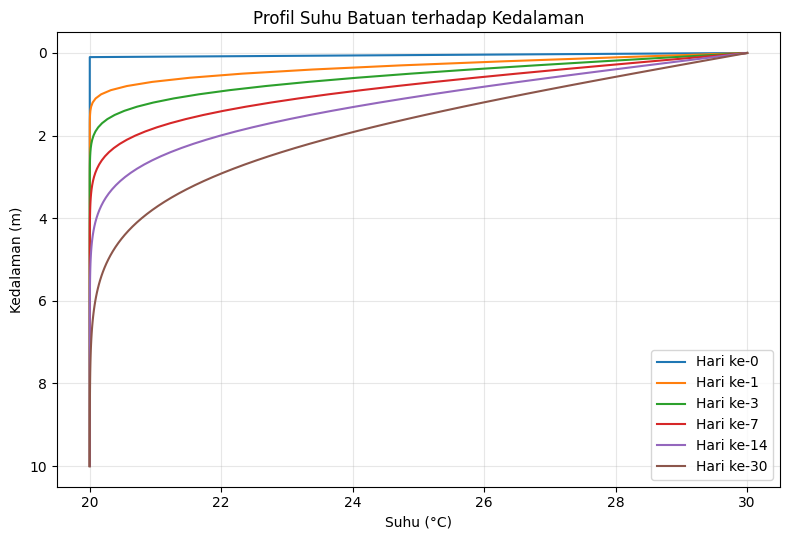

In [3]:
plt.figure(figsize=(8, 5.5))
for h in hari_pilihan:
    if h in profil:
        plt.plot(profil[h], z, label=f"Hari ke-{h}")
plt.gca().invert_yaxis()
plt.xlabel("Suhu (°C)")
plt.ylabel("Kedalaman (m)")
plt.title("Profil Suhu Batuan terhadap Kedalaman")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 6.2 Evolusi suhu terhadap waktu dan kedalaman

Peta warna menunjukkan bagaimana perubahan suhu berkembang selama simulasi. Sumbu horizontal menyatakan waktu dalam hari, sumbu vertikal menyatakan kedalaman, dan warna menyatakan suhu.

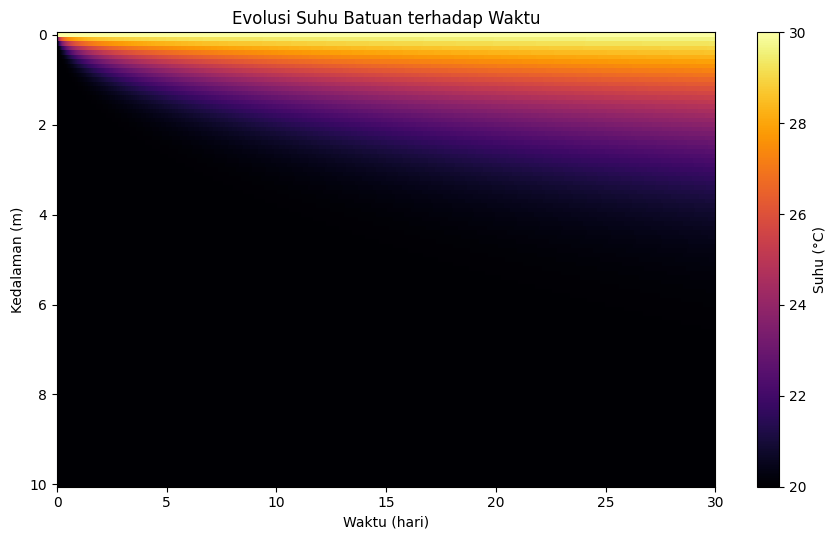

In [4]:
waktu_hari = waktu / 86400.0

plt.figure(figsize=(9, 5.5))
pcm = plt.pcolormesh(waktu_hari, z, hasil.T, shading="auto", cmap="inferno")
plt.gca().invert_yaxis()
plt.xlabel("Waktu (hari)")
plt.ylabel("Kedalaman (m)")
plt.title("Evolusi Suhu Batuan terhadap Waktu")
plt.colorbar(pcm, label="Suhu (°C)")
plt.tight_layout()
plt.show()

### 6.3 Tabel suhu pada kedalaman pengamatan

Suhu pada kedalaman 1 m ditampilkan untuk hari pengamatan yang telah ditentukan. Angka akan dihitung langsung dari hasil simulasi ketika sel dijalankan.

In [5]:
kedalaman_uji = 1.0
indeks = int(np.argmin(np.abs(z - kedalaman_uji)))

ringkasan = []
for h in hari_pilihan:
    if h in profil:
        ringkasan.append({
            "Hari simulasi": h,
            "Kedalaman (m)": z[indeks],
            "Suhu (°C)": profil[h][indeks]
        })

tabel_ringkasan = pd.DataFrame(ringkasan)
display(tabel_ringkasan.round(4))

,Hari simulasi,Kedalaman (m),Suhu (°C)
0,0,1.0,20.0000
1,1,1.0,20.1731
2,3,1.0,21.6605
3,7,1.0,23.6349
4,14,1.0,25.2041
5,30,1.0,26.6054


## 7. Pembahasan

Interpretasi akhir perlu merujuk pada grafik dan tabel yang dihasilkan saat notebook dijalankan.

Secara fisik, kenaikan suhu pada batas permukaan menimbulkan gradien suhu antara bagian permukaan dan interior batuan. Gradien ini mendorong perpindahan energi melalui konduksi. Perubahan suhu paling besar diharapkan berada di dekat permukaan, sementara lapisan yang lebih dalam merespons lebih lambat. Dengan bertambahnya waktu, gangguan termal dapat menjalar lebih jauh ke bawah permukaan.

Besarnya respons pada kedalaman tertentu dipengaruhi oleh difusivitas termal. Secara umum, difusivitas yang lebih besar memungkinkan perubahan suhu menyebar lebih cepat. Namun, hasil simulasi juga bergantung pada kondisi batas, kondisi awal, durasi simulasi, serta resolusi ruang dan waktu.

Model ini bersifat ideal karena menganggap medium homogen dan hanya mempertimbangkan konduksi vertikal. Pada sistem geologi nyata, variasi litologi, porositas, kandungan air, aliran fluida, topografi, dan sumber panas internal dapat mengubah distribusi suhu. Oleh sebab itu, hasilnya sebaiknya dipahami sebagai demonstrasi konsep, bukan estimasi suhu aktual pada lokasi tertentu.

### Pemeriksaan numerik

Faktor stabilitas $r$ dihitung sebelum iterasi. Jika $r\leq0{,}5$, skema eksplisit memenuhi syarat kestabilan untuk persamaan difusi satu dimensi pada grid seragam. Kestabilan numerik tidak dengan sendirinya menjamin bahwa parameter model sesuai dengan kondisi geologi nyata.

## 8. Kesimpulan

Praktikum ini memodelkan perambatan panas satu dimensi pada batuan homogen menggunakan persamaan difusi panas dan metode beda hingga eksplisit. Simulasi menghasilkan profil suhu terhadap kedalaman, peta evolusi suhu terhadap waktu, dan tabel suhu pada kedalaman 1 m.

Model memperlihatkan cara numerik untuk mempelajari respons termal bawah permukaan terhadap gangguan suhu permukaan. Interpretasi kuantitatif harus didasarkan pada keluaran aktual notebook. Karena parameter bersifat ilustratif dan proses yang dimodelkan hanya konduksi, hasil ini tidak dapat langsung digunakan untuk menyimpulkan kondisi sistem panas bumi nyata tanpa data lapangan dan model yang lebih lengkap.

## 9. Referensi

1. Smerdon, J. E., Pollack, H. N., Enz, J. W., & Lewis, M. J. (2006). *Simulation of the thermal diffusion of annual temperature signals into the ground: Implications for climate reconstruction*. Journal of Geophysical Research: Atmospheres. https://doi.org/10.1029/2005JD006592

2. Carslaw, H. S., & Jaeger, J. C. (1959). *Conduction of Heat in Solids* (2nd ed.). Oxford University Press.

